# CNN Development on Custom Dataset: Mosquito Species Recognition on Human Skin

**Name:** Abdul Al-Abrar Shahriyar | **ID:** 23-50648-1 | **Course:** CVPR (Mid Assignment)

**Dataset:** Mosquito-on-human-skin (Ong & Ahmad, 2022), licence CC BY 4.0
- Kaggle: https://www.kaggle.com/datasets/naiborhujosua/mosquito-on-human-skin

**Goal:** design and train a custom CNN from scratch that classifies a photo into six classes:
three mosquito species (*Aedes aegypti*, *Aedes albopictus*, *Culex quinquefasciatus*), each either **landing** on human skin or **smashed** on it.

**Notebook structure:** 1. Import Libraries, 2. Load and Explore Dataset, 3. Data Preprocessing & Augmentation, 4. Define CNN Architecture, 5. Training Loop with Validation, 6. Evaluate Model on Test Set, 7. Visualizations, 8. Analysis & Discussion of Results, 9. Conclusions & Future Work.

## 1. Import Libraries

PyTorch and torchvision are used to build and train the CNN. scikit-learn is used only for the stratified split and for the evaluation metrics. Every random seed is fixed at 42 so that the data split and the results can be reproduced. The last line checks that the GPU is available.

In [ ]:
import os, random, copy
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import torch
import torch.nn as nn
from torch.optim import Adam
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets
import torchvision.transforms as transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Fix every random seed so the split and the results can be reproduced
SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


## 2. Load and Explore Dataset

**Source.** The dataset is *Mosquito-on-human-skin* by Song-Quan Ong (Universiti Malaysia Sabah), published on Mendeley Data under CC BY 4.0, mirrored on Kaggle, and described in the journal *Scientific Data* (2022).

**Content.** 1,500 original photos, exactly 250 per class, so the classes are balanced. All photos are 224x224 RGB JPEG files.

**Classes.** Three species, each in two conditions, which gives six classes:

| Species | Why it matters | Conditions |
| --- | --- | --- |
| *Aedes aegypti* | main dengue vector | landing, smashed |
| *Aedes albopictus* | second dengue vector | landing, smashed |
| *Culex quinquefasciatus* | common house mosquito | landing, smashed |

**Capture.** The mosquitoes came from a WHO-accredited breeding laboratory, which is why the species labels are reliable. They were photographed on human skin with a Canon 7D DSLR and a 90 mm macro lens.

**Why this problem.** Dengue is carried by *Aedes* mosquitoes. Bangladesh recorded 132,948 dengue infections and 384 deaths between January 1 and October 25, 2026 (Dhaka Tribune, 26 Oct 2026). Telling a dengue vector apart from the harmless-looking house mosquito, even after it has been smashed, is a practical recognition task.

The dataset is downloaded with `kagglehub`, the same way as in the reference Cat and Dog example.

In [ ]:
import kagglehub
SOURCE = 'Kaggle: naiborhujosua/mosquito-on-human-skin'
try:
    path = kagglehub.dataset_download("naiborhujosua/mosquito-on-human-skin")
except Exception as e:
    print('Kaggle download failed:', e)
    path = None
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'mosquito-on-human-skin' dataset.
Path to dataset files: /kaggle/input/mosquito-on-human-skin


The download contains the six original class folders and one extra folder called `data_splitting`. Only the six original folders are used (the reason is shown in the evidence cell below). They are linked into one clean folder so that `ImageFolder` sees exactly six classes with short names.

In [ ]:
def find_raw_class_folders(root):
    """The six ORIGINAL photo folders. 'data_splitting' is skipped on purpose:
    its Test/Pred images are rotated copies of Train images (data leakage)."""
    found = {}
    for d, subdirs, files in os.walk(root):
        subdirs[:] = [s for s in subdirs if s != 'data_splitting']
        name = os.path.basename(d).lower()
        if ('landing' in name or 'smashed' in name) and any(f.lower().endswith(('.jpg', '.jpeg', '.png')) for f in files):
            species = 'aegypti' if 'aegypti' in name else 'albopictus' if 'albopictus' in name else 'culex'
            found[f"{species}_{'landing' if 'landing' in name else 'smashed'}"] = d
    return dict(sorted(found.items()))

class_dirs = find_raw_class_folders(path) if path else {}
if len(class_dirs) != 6:
    # Fallback: a public GitHub mirror of the same Mendeley dataset
    print('Six original class folders not found in the Kaggle copy -> using the GitHub mirror')
    !test -d /content/mosquito_mirror || git clone -q --depth 1 https://github.com/harbidel/Mosquito-on-human-skin-prediction-model /content/mosquito_mirror
    path = '/content/mosquito_mirror'
    SOURCE = 'GitHub mirror of the Mendeley dataset'
    class_dirs = find_raw_class_folders(path)
assert len(class_dirs) == 6, class_dirs

raw_root = '/content/mosquito_raw'          # clean ImageFolder root: 6 class folders only
os.makedirs(raw_root, exist_ok=True)
for cls, src in class_dirs.items():
    if not os.path.exists(f'{raw_root}/{cls}'):
        os.symlink(src, f'{raw_root}/{cls}')
print('Data source:', SOURCE)
print({c: len(os.listdir(d)) for c, d in class_dirs.items()})   # expect 250 each

Data source: Kaggle: naiborhujosua/mosquito-on-human-skin
{'aegypti_landing': 250, 'aegypti_smashed': 250, 'albopictus_landing': 250, 'albopictus_smashed': 250, 'culex_landing': 250, 'culex_smashed': 250}


Total images       : 1500
Classes and indices: {'aegypti_landing': 0, 'aegypti_smashed': 1, 'albopictus_landing': 2, 'albopictus_smashed': 3, 'culex_landing': 4, 'culex_smashed': 5}
Images per class   : {'aegypti_landing': 250, 'aegypti_smashed': 250, 'albopictus_landing': 250, 'albopictus_smashed': 250, 'culex_landing': 250, 'culex_smashed': 250}
First image (W, H) and mode: (224, 224) RGB


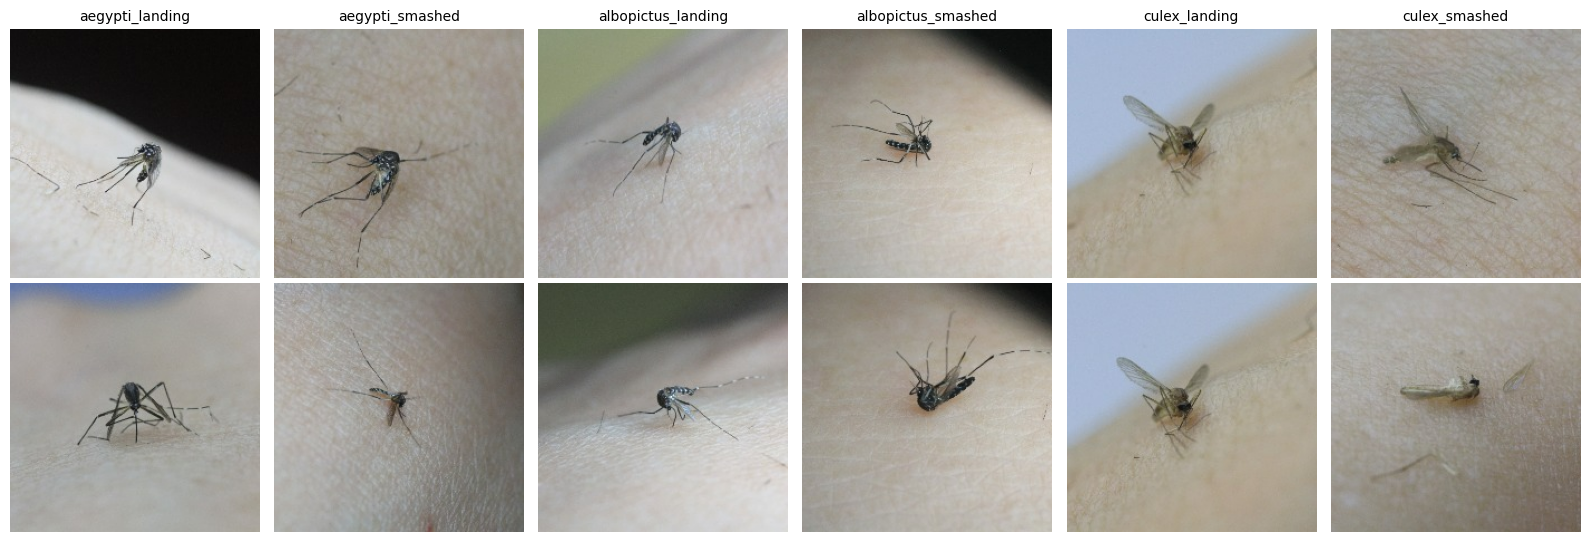

In [ ]:
full_data = datasets.ImageFolder(raw_root)     # no transform yet, so items are PIL images
class_names = full_data.classes
num_classes = len(class_names)
targets = np.array(full_data.targets)

print('Total images       :', len(full_data))
print('Classes and indices:', full_data.class_to_idx)
print('Images per class   :', dict(zip(class_names, np.bincount(targets).tolist())))
print('First image (W, H) and mode:', full_data[0][0].size, full_data[0][0].mode)

# Two sample photos from every class
fig, axes = plt.subplots(2, num_classes, figsize=(16, 5.5))
for c, name in enumerate(class_names):
    for r, i in enumerate(np.where(targets == c)[0][:2]):
        img, _ = full_data[int(i)]
        axes[r, c].imshow(img)
        axes[r, c].axis('off')
        if r == 0:
            axes[r, c].set_title(name, fontsize=10)
plt.tight_layout()
plt.show()

### Why the ready-made `data_splitting` folder is not used

The dataset also ships with a ready-made split (`data_splitting/Train`, `Test`, `Pred`). According to the data paper it was produced by rotating every photo by 0, 90, 180 and 270 degrees and then partitioning the result. If rotation happens before splitting, copies of the same photo can land on both sides. The cell below checks this directly: (a) it counts files that are byte-identical between `Train` and `Pred`, and (b) for every `Test` image it looks for a `Train` image that is the same picture after a 0/90/180/270 degree rotation (correlation of 16x16 grayscale thumbnails of at least 0.97).

In [ ]:
# Evidence cell: why the ready-made "data_splitting" folder is NOT used
import hashlib
from PIL import Image

IMG = ('.jpg', '.jpeg', '.png')
def list_images(folder):
    return sorted(os.path.join(d, f) for d, _, fs in os.walk(folder) for f in fs if f.lower().endswith(IMG))

def md5(p):
    with open(p, 'rb') as fh:
        return hashlib.md5(fh.read()).hexdigest()

def tiny(p, k=0):
    """16x16 grayscale thumbnail, rotated k*90 degrees and standardised."""
    a = np.asarray(Image.open(p).convert('L').resize((16, 16)), dtype=np.float32)
    a = np.rot90(a, k).ravel()
    return (a - a.mean()) / (a.std() + 1e-6)

# locate data_splitting/Train, /Test, /Pred (folder-name case can vary)
split_dir = next((os.path.join(d, s) for d, subs, _ in os.walk(path) for s in subs if s.lower() == 'data_splitting'), None)
if split_dir is None:
    print('This copy has no data_splitting folder, so there is nothing to check.')
else:
    parts = {s.lower(): list_images(os.path.join(split_dir, s)) for s in os.listdir(split_dir)}
    train_f, test_f, pred_f = parts.get('train', []), parts.get('test', []), parts.get('pred', [])
    print('Ready-made split sizes  Train:', len(train_f), ' Test:', len(test_f), ' Pred:', len(pred_f))

    # (a) byte-identical files shared by Train and Pred
    train_hashes = {md5(p) for p in train_f}
    same = sum(md5(p) in train_hashes for p in pred_f)
    print(f'Pred files that are byte-identical to a Train file: {same} / {len(pred_f)}')

    # (b) Test images that are a rotated copy of a Train image
    T = np.stack([tiny(p) for p in train_f])                    # (n_train, 256)
    hits = 0
    for p in test_f:
        best = max(float((T @ tiny(p, k)).max()) / 256 for k in range(4))   # best correlation over 4 rotations
        hits += best >= 0.97
    print(f'Test images with a rotated near-copy in Train: {hits} / {len(test_f)} ({100 * hits / len(test_f):.1f}%)')

Ready-made split sizes  Train: 4200  Test: 1799  Pred: 3600
Pred files that are byte-identical to a Train file: 1800 / 3600
Test images with a rotated near-copy in Train: 1767 / 1799 (98.2%)


<<P2>>

## 3. Data Preprocessing & Augmentation

All hyperparameters are kept in one cell, as in the reference example. The 1,500 original photos are split **first** (stratified 70 / 15 / 15, seed 42) and augmentation is applied **afterwards and only to the training part**. This order is what keeps the validation and test sets clean: no version of a validation or test photo is ever seen during training.

- **Training transform:** resize to 128x128, random horizontal and vertical flips, random rotation of up to 20 degrees, small brightness/contrast changes, then conversion to a tensor in [0, 1].
- **Validation and test transform:** resize and tensor conversion only, so evaluation is identical every time.

In [ ]:
## Hyperparameters ##
size = 224             # input image size (pixels) = native size of the photos
batch_size = 32
learning_rate = 1e-3   # starting value, lowered by cosine annealing during training
weight_decay = 1e-4    # L2 regularisation inside Adam
dropout = 0.4
epoch_number = 100

In [ ]:
# Training images: resize + random augmentation (a new random version every epoch)
train_transform = transforms.Compose([
    transforms.Resize((size, size)),                        # safety resize (the photos are already 224x224)
    transforms.RandomHorizontalFlip(),                      # a mosquito can face left or right
    transforms.RandomVerticalFlip(),                        # ... or up or down
    transforms.RandomChoice([transforms.RandomRotation((a, a)) for a in (0, 90, 180, 270)]),   # random quarter turn (no black corners)
    transforms.ColorJitter(brightness=0.2, contrast=0.2),   # lighting changes only, colour is kept
    transforms.ToTensor()                                   # PIL -> float tensor in [0.0, 1.0]
])

# Validation and test images: resize only, no randomness
val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

# Stratified 70 / 15 / 15 split of the 1,500 original photos (every class keeps the same share)
indices = np.arange(len(full_data))
train_idx, temp_idx = train_test_split(indices, test_size=0.30, stratify=targets, random_state=SEED)
val_idx, test_idx = train_test_split(temp_idx, test_size=0.50, stratify=targets[temp_idx], random_state=SEED)

class MosquitoSubset(Dataset):
    """One part of the full dataset (train, val or test) with its own transform."""
    def __init__(self, base, indices, transform):
        self.base = base
        self.indices = [int(i) for i in indices]
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, ix):
        img, label = self.base[self.indices[ix]]
        return self.transform(img), label

train_data = MosquitoSubset(full_data, train_idx, train_transform)
val_data = MosquitoSubset(full_data, val_idx, val_transform)
test_data = MosquitoSubset(full_data, test_idx, val_transform)

print('Dataset Summary')
print('Train Data: ', len(train_data))
print('Validation Data: ', len(val_data))
print('Test Data: ', len(test_data))
for name, idx in [('train', train_idx), ('val', val_idx), ('test', test_idx)]:
    print(f'  {name:5s} per class:', np.bincount(targets[idx]).tolist())
# No photo may appear in two splits
assert not (set(train_idx) & set(val_idx)) and not (set(train_idx) & set(test_idx)) and not (set(val_idx) & set(test_idx))

Dataset Summary
Train Data:  1050
Validation Data:  225
Test Data:  225
  train per class: [175, 175, 175, 175, 175, 175]
  val   per class: [38, 38, 37, 37, 37, 38]
  test  per class: [37, 37, 38, 38, 38, 37]


Batch shape: torch.Size([32, 3, 224, 224]) | labels shape: torch.Size([32]) | pixel range: 0.0 to 1.0


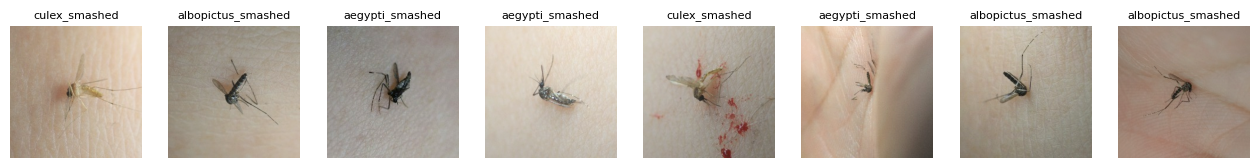

In [ ]:
trn_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=2)
test_dl = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)

# Look at one augmented training batch
x, y = next(iter(trn_dl))
print('Batch shape:', x.shape, '| labels shape:', y.shape, '| pixel range:', x.min().item(), 'to', x.max().item())
fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
for ax, img, lab in zip(axes, x, y):
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(class_names[lab.item()], fontsize=8)
    ax.axis('off')
plt.show()

### Hyperparameter details and rationale

| Hyperparameter | Value | Rationale |
| --- | --- | --- |
| Input size | 128x128 | The mosquito is a small part of each photo. At 32x32 the leg and body markings disappear, while the full 224x224 costs about three times the computation. |
| Split | 70 / 15 / 15, stratified, seed 42 | Every class keeps the same share in each part (175 / 37-38 / 37-38 images) and the split is reproducible. |
| Batch size | 32 | Same as the reference example. Gives 33 weight updates per epoch on 1,050 images. |
| Flips and rotation | horizontal, vertical, up to 20 degrees | A mosquito can sit at any angle, so these produce realistic new views. |
| Colour jitter | brightness and contrast 0.2 only | Lighting varies between photos, but body colour and blood are real class cues, so hue and saturation are left alone. |
| Optimizer | Adam | Adapts the step size for every weight and converges quickly without tuning. |
| Learning rate | 1e-3 (halved on plateau) | Adam's standard starting value and the value in the reference example. |
| Weight decay | 1e-4 | Mild L2 penalty against overfitting on a small dataset. |
| Dropout | 0.4 | Stops the classifier from relying on a few features. |
| Epochs | 40 | Augmented images differ every epoch, so learning is slower. The weights of the best validation epoch are kept. |
| Loss | Cross-entropy | Standard loss for a single-label multi-class problem. |

## 4. Define CNN Architecture

The model is a custom CNN written with `nn.Sequential` inside `get_model()`, following the structure of the reference example. It has four convolution blocks for feature extraction and a small classifier.

| Stage | Layers | Output shape | Parameters |
| --- | --- | --- | --- |
| Input | RGB image | 3 x 128 x 128 | 0 |
| Block 1 | Conv 3x3 (32), BatchNorm, ReLU, MaxPool | 32 x 64 x 64 | 960 |
| Block 2 | Conv 3x3 (64), BatchNorm, ReLU, MaxPool | 64 x 32 x 32 | 18,624 |
| Block 3 | Conv 3x3 (128), BatchNorm, ReLU, MaxPool | 128 x 16 x 16 | 74,112 |
| Block 4 | Conv 3x3 (256), BatchNorm, ReLU, MaxPool | 256 x 8 x 8 | 295,680 |
| Pooling | Global average pooling, Flatten | 256 | 0 |
| Classifier | Linear 256 -> 128, ReLU, Dropout 0.4 | 128 | 32,896 |
| Output | Linear 128 -> 6 | 6 class scores | 774 |

**Justification.**
- **3x3 convolutions with padding 1** keep the number of parameters low and keep the spatial size, so only the pooling layers shrink the image.
- **The number of filters doubles in every block (32, 64, 128, 256).** Early layers detect edges and colours; later layers combine them into legs, wings and body patterns, which needs more channels.
- **Four blocks** reduce 128x128 to 8x8, so each final feature covers a large part of the photo.
- **Batch normalisation after every convolution** keeps activations in a stable range, which makes training start quickly and tolerate a learning rate of 1e-3.
- **Global average pooling** replaces a large fully connected layer. Flattening 256 x 8 x 8 into a Linear layer of 128 units would need more than 2 million weights; averaging needs none, which suits a training set of 1,050 images.
- **Dropout 0.4** regularises the only large fully connected layer.
- **No softmax layer at the end**, because `nn.CrossEntropyLoss` applies log-softmax internally.
- The whole model has **423,046 trainable parameters**, about one third of the reference Cat and Dog model (1,256,066).

In [ ]:
def conv_block(in_channels, out_channels):
    """Conv 3x3 -> BatchNorm -> ReLU -> MaxPool. Halves the height and width."""
    return [
        nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(),
        nn.MaxPool2d(2),
    ]

def get_model():
    model = nn.Sequential(
        # Feature Extraction
        *conv_block(3, 32),       # 224 -> 112
        *conv_block(32, 64),      # 112 -> 56
        *conv_block(64, 128),     #  56 -> 28
        *conv_block(128, 256),    #  28 -> 14
        *conv_block(256, 256),    #  14 -> 7

        # Classifier
        nn.AdaptiveAvgPool2d(1),  # global average pooling: 256 x 7 x 7 -> 256 x 1 x 1
        nn.Flatten(),
        nn.Linear(256, 128),
        nn.ReLU(),
        nn.Dropout(dropout),
        nn.Linear(128, num_classes)
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    return model, loss_fn, optimizer

The detailed layer-by-layer summary (output shape and parameter count of every layer):

In [ ]:
try:
    from torchsummary import summary
except ImportError:
    !pip -q install torchsummary
    from torchsummary import summary

model, loss_fn, optimizer = get_model()
summary(model, input_size=(3, size, size), device=device);

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 224, 224]             896
       BatchNorm2d-2         [-1, 32, 224, 224]              64
              ReLU-3         [-1, 32, 224, 224]               0
         MaxPool2d-4         [-1, 32, 112, 112]               0
            Conv2d-5         [-1, 64, 112, 112]          18,496
       BatchNorm2d-6         [-1, 64, 112, 112]             128
              ReLU-7         [-1, 64, 112, 112]               0
         MaxPool2d-8           [-1, 64, 56, 56]               0
            Conv2d-9          [-1, 128, 56, 56]          73,856
      BatchNorm2d-10          [-1, 128, 56, 56]             256
             ReLU-11          [-1, 128, 56, 56]               0
        MaxPool2d-12          [-1, 128, 28, 28]               0
           Conv2d-13          [-1, 256, 28, 28]         295,168
      BatchNorm2d-14          [-1, 256,

## 5. Training Loop with Validation

**Training protocol.**
- **Optimizer: Adam** (learning rate 1e-3, weight decay 1e-4), created inside `get_model()`.
- **Loss: cross-entropy**, because the six classes are mutually exclusive.
- **Validation after every epoch.** The validation set is never used for weight updates; it only shows when the model stops generalising.
- **ReduceLROnPlateau scheduler.** When the validation loss has not improved for 4 epochs the learning rate is halved, so the model takes large steps early and small steps later.
- **Best-epoch weights.** The weights from the epoch with the highest validation accuracy are stored and restored after training. The test set is not touched until Section 6.

`train_one_epoch()` and `validation()` are the same functions as in the reference example.

In [ ]:
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)

@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)

In [ ]:
## Training Loop ##
# Cosine annealing: the learning rate falls smoothly from 1e-3 to almost 0 over all epochs
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epoch_number)

train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []
best_val_acc, best_epoch, best_state = 0.0, 0, None

for epoch in range(epoch_number):
    epoch_loss, epoch_accuracy = train_one_epoch(trn_dl, model, loss_fn, optimizer)
    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    v_loss, v_acc = validation(val_dl, model, loss_fn)
    val_losses.append(v_loss)
    val_accuracies.append(v_acc)

    # Remember the weights from the epoch with the best validation accuracy
    if v_acc > best_val_acc:
        best_val_acc, best_epoch = v_acc, epoch + 1
        best_state = copy.deepcopy(model.state_dict())

    print(f"Epoch [{epoch + 1}/{epoch_number}]"
          f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
          f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%"
          f" | LR: {optimizer.param_groups[0]['lr']:.5f}")
    scheduler.step()   # lower the learning rate for the next epoch

# Go back to the best epoch before testing
model.load_state_dict(best_state)
print(f"Best validation accuracy: {best_val_acc*100:.2f}% at epoch {best_epoch}")

Epoch [1/100] | Train Loss: 1.6593 | Train Accuracy: 30.19% | Val Loss: 1.8427 | Val Accuracy: 16.89% | LR: 0.00100
Epoch [2/100] | Train Loss: 1.5207 | Train Accuracy: 39.05% | Val Loss: 1.5975 | Val Accuracy: 34.67% | LR: 0.00100
Epoch [3/100] | Train Loss: 1.3568 | Train Accuracy: 43.90% | Val Loss: 1.4177 | Val Accuracy: 43.56% | LR: 0.00100
Epoch [4/100] | Train Loss: 1.2201 | Train Accuracy: 50.29% | Val Loss: 4.7560 | Val Accuracy: 24.89% | LR: 0.00100
Epoch [5/100] | Train Loss: 1.1560 | Train Accuracy: 52.57% | Val Loss: 1.6617 | Val Accuracy: 40.89% | LR: 0.00100
Epoch [6/100] | Train Loss: 1.1119 | Train Accuracy: 55.14% | Val Loss: 1.1789 | Val Accuracy: 53.78% | LR: 0.00099
Epoch [7/100] | Train Loss: 1.1401 | Train Accuracy: 54.67% | Val Loss: 2.7634 | Val Accuracy: 32.00% | LR: 0.00099
Epoch [8/100] | Train Loss: 1.0534 | Train Accuracy: 57.24% | Val Loss: 2.0679 | Val Accuracy: 34.22% | LR: 0.00099
Epoch [9/100] | Train Loss: 1.0089 | Train Accuracy: 58.76% | Val Loss: 

## 6. Evaluate Model on Test Set

The test set (225 original photos that were never used for training or for choosing the best epoch) is evaluated once. Reported metrics: test loss, test accuracy, precision, recall and F1-score for every class, and the confusion matrix. Because every class is one species in one condition, two extra numbers are also printed: how often the **species** is right and how often the **condition** (landing or smashed) is right.

Test Loss : 0.2259 , Test Accuracy: 91.56%
                    precision    recall  f1-score   support

   aegypti_landing      0.892     0.892     0.892        37
   aegypti_smashed      0.939     0.838     0.886        37
albopictus_landing      0.895     0.895     0.895        38
albopictus_smashed      0.854     0.921     0.886        38
     culex_landing      0.927     1.000     0.962        38
     culex_smashed      1.000     0.946     0.972        37

          accuracy                          0.916       225
         macro avg      0.918     0.915     0.915       225
      weighted avg      0.917     0.916     0.915       225



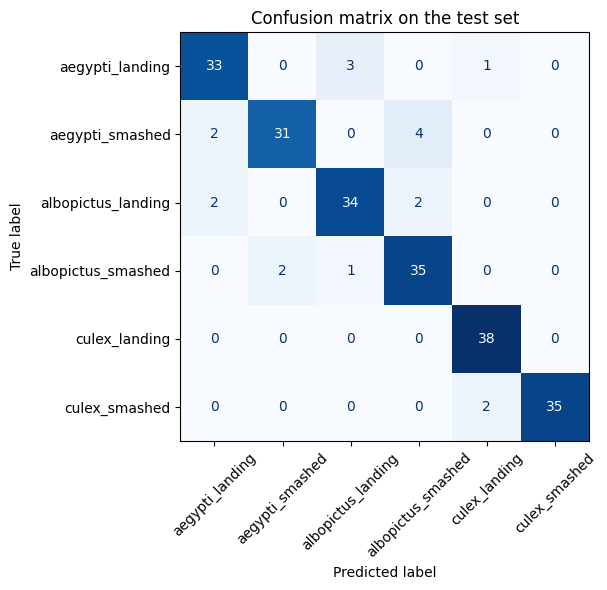

Species correct (3-way)        : 94.67%
Landing vs smashed correct     : 96.89%


In [ ]:
test_loss, test_acc = validation(test_dl, model, loss_fn)
print(f'Test Loss : {test_loss:0.4f} , Test Accuracy: {test_acc*100:0.2f}%')

@torch.no_grad()
def get_predictions(data_loader, model):
    """True and predicted class index for every image in a loader."""
    model.eval()
    y_true, y_pred = [], []
    for x, y in data_loader:
        prediction = model(x.to(device))
        y_true.extend(y.tolist())
        y_pred.extend(prediction.argmax(-1).cpu().tolist())
    return np.array(y_true), np.array(y_pred)

y_true, y_pred = get_predictions(test_dl, model)

# Precision, recall and F1-score for every class
print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

# Confusion matrix: rows = true class, columns = predicted class
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap='Blues', xticks_rotation=45, colorbar=False)
plt.title('Confusion matrix on the test set')
plt.tight_layout()
plt.show()

# Species-only and condition-only accuracy (class names look like "aegypti_landing")
species = lambda idx: np.array([class_names[i].split('_')[0] for i in idx])
state = lambda idx: np.array([class_names[i].split('_')[1] for i in idx])
print(f'Species correct (3-way)        : {(species(y_true) == species(y_pred)).mean()*100:.2f}%')
print(f'Landing vs smashed correct     : {(state(y_true) == state(y_pred)).mean()*100:.2f}%')

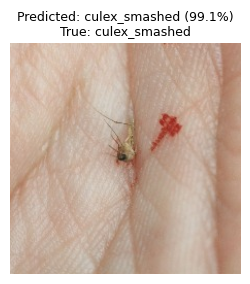

In [ ]:
# Predict one test image and show the confidence
test_img, label = test_data[2]
model.eval()
with torch.no_grad():
    output = model(test_img.unsqueeze(0).to(device))
    pred = torch.softmax(output, dim=-1)
confidence, index = pred.max(-1)

plt.figure(figsize=(3, 3))
plt.imshow(test_img.permute(1, 2, 0))
plt.title(f'Predicted: {class_names[index.item()]} ({confidence.item()*100:0.1f}%)\nTrue: {class_names[label]}', fontsize=9)
plt.axis('off')
plt.show()

### Saving and loading the trained model

Only the learned weights (`state_dict`) are saved to `model.pth`, as in the reference Model Save and Load example. To prove the file works, a brand-new model is created with `get_model()`, the weights are loaded into it, and the test set is evaluated again.

In [ ]:
# Save only the learned weights (state_dict), as in the Model Save and Load example
torch.save(model.state_dict(), 'model.pth')
print(f"Saved model.pth ({os.path.getsize('model.pth') / 1e6:.2f} MB)")

# Load the weights into a brand-new model and check it gives the same test result
saved_model = get_model()[0]
saved_model.load_state_dict(torch.load('model.pth', map_location=device))
saved_model.eval()

re_loss, re_acc = validation(test_dl, saved_model, loss_fn)
print(f'Reloaded model -> Test Loss : {re_loss:0.4f} , Test Accuracy: {re_acc*100:0.2f}%')

Saved model.pth (4.07 MB)
Reloaded model -> Test Loss : 0.2259 , Test Accuracy: 91.56%


<<P6>>

## 7. Visualizations (Loss/Accuracy Curves)

Training and validation loss (left) and accuracy (right) for every epoch. The dashed line marks the epoch whose weights were kept.

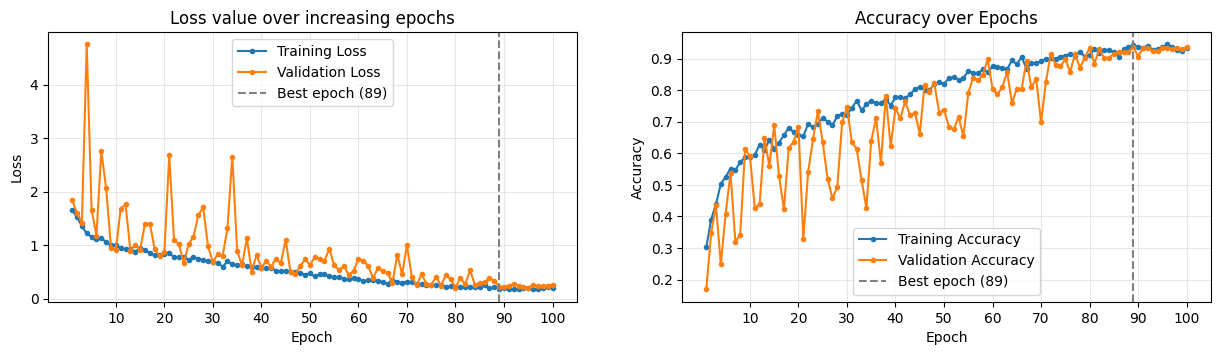

In [ ]:
epochs = np.arange(epoch_number) + 1
plt.figure(figsize=(15, 3.5))

plt.subplot(121)
plt.title("Loss value over increasing epochs")
plt.plot(epochs, train_losses, marker='o', markersize=3, label="Training Loss")
plt.plot(epochs, val_losses, marker='o', markersize=3, label="Validation Loss")
plt.axvline(best_epoch, color='gray', linestyle='--', label=f"Best epoch ({best_epoch})")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs[9::10])
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(122)
plt.title("Accuracy over Epochs")
plt.plot(epochs, train_accuracies, marker='o', markersize=3, label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker='o', markersize=3, label="Validation Accuracy")
plt.axvline(best_epoch, color='gray', linestyle='--', label=f"Best epoch ({best_epoch})")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs[9::10])
plt.legend()
plt.grid(alpha=0.3)
plt.show()

<<P7>>

<<P8>>

<<P9>>